Um distribuidor atacadista atende, ao mesmo tempo, clientes muito diferentes entre si: o restaurante que compra
hortifr´uti e congelados em alto giro, o pequeno mercado de bairro que se abastece de mercearia, latic´ınios e produtos
de limpeza, entre outros. Tratar todos eles com a mesma pol´ıtica comercial e, na pr ´ atica, desperdic¸ar margem e ´
capacidade log´ıstica.
A segmentac¸ao de clientes tem aplicac¸ ˜ oes diretas no planejamento de rotas e estoques, na definic¸ ˜ ao de campanhas ˜
promocionais dirigidas, na concessao de limites de cr ˜ edito e na identificac¸ ´ ao de clientes at ˜ ´ıpicos, que merecem
atendimento dedicado. No Brasil, o crescimento do modelo de atacarejo e a importancia dos distribuidores regionais ˆ
no abastecimento do interior do Nordest, tornam o problema especialmente concreto para a nossa realidade.
Este projeto tem uma caracter´ıstica que o dist
ingue dos anteriores: nao existe um r ˜ otulo a ser previsto. Ningu ´ em´
classificou previamente os clientes em “perfil restaurante” ou “perfil varejo’, se esses grupos existem, eles precisam
emergir da propria estrutura dos gastos. ´ E o dom ´ ´ınio do aprendizado nao supervisionado. ˜
Neste projeto, voceˆ e convidado a identificar perfis de consumo de clientes de um distribuidor atacadista por meio do ´
algoritmo de agrupamento 𝑘-Means.
O projeto utiliza o arquivo Wholesale customers data.csv do dataset Wholesale Customers (https://archive.
ics.uci.edu/dataset/292/wholesale+customers). O dataset foi doado por Margarida G. M. S. Cardoso
(ISCTE-IUL, Lisboa, Portugal) em 2014 e re´une 440 clientes de um distribuidor atacadista portugues. Para cada cli- ˆ
ente sao registrados os gastos anuais, em unidades monet ˜ arias, em seis categorias de produto — ´ Fresh (frescos), Milk
(latic´ınios), Grocery (mercearia), Frozen (congelados), Detergents Paper (detergentes e papel) e Delicassen
(delicatessen) — alem de dois atributos categ ´ oricos: ´ Channel, indicando se o cliente pertence ao canal Horeca (hoteis, ´
restaurantes e cafes, 298 clientes) ou ´ Retail (varejo, 142 clientes), e Region, indicando sua localizac¸ao (Lisboa, Porto ˜
ou outras regioes). ˜
Observac¸ao: ˜ os atributos Channel e Region nao˜ devem ser utilizados no agrupamento. Eles serao reservados para ˜
a validac¸ao externa da tarefa 5. O agrupamento deve basear-se exclusivamente nas seis categorias de gasto. ˜
Realize as seguintes tarefas utilizando o dataset fornecido:

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from scipy.spatial.distance import cdist
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.datasets import make_blobs, make_moons
from sklearn.metrics import (silhouette_score, silhouette_samples,
                             calinski_harabasz_score, davies_bouldin_score,
                             adjusted_rand_score)

In [2]:
plt.rcParams["font.family"] = "Arial"
plt.rcParams["mathtext.fontset"] = "custom"
plt.rcParams['mathtext.rm'] = "Arial"
plt.rcParams['mathtext.it'] = "Arial:italic"
plt.rcParams['mathtext.bf'] = "Arial:bold"
plt.rcParams['figure.figsize'] = (8, 5)

In [3]:
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
wholesale_customers = fetch_ucirepo(id=292) 

# chanel vem junto ao X
# data (as pandas dataframes) 
X = wholesale_customers.data.features 
y = wholesale_customers.data.targets 

y = y.copy()
y['Channel'] = X['Channel']

X = X.drop('Channel', axis=1)
  
# metadata 
print(wholesale_customers.metadata) 
  
# variable information 
print(wholesale_customers.variables) 


{'uci_id': 292, 'name': 'Wholesale customers', 'repository_url': 'https://archive.ics.uci.edu/dataset/292/wholesale+customers', 'data_url': 'https://archive.ics.uci.edu/static/public/292/data.csv', 'abstract': 'The data set refers to clients of a wholesale distributor. It includes the annual spending in monetary units (m.u.) on diverse product categories', 'area': 'Business', 'tasks': ['Classification', 'Clustering'], 'characteristics': ['Multivariate'], 'num_instances': 440, 'num_features': 7, 'feature_types': ['Integer'], 'demographics': [], 'target_col': ['Region'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2013, 'last_updated': 'Mon Feb 05 2024', 'dataset_doi': '10.24432/C5030X', 'creators': ['Margarida Cardoso'], 'intro_paper': None, 'additional_info': {'summary': None, 'purpose': None, 'funded_by': None, 'instances_represent': None, 'recommended_data_splits': None, 'sensitive_data': None, 'preprocessing_description':

In [4]:
X

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,12669,9656,7561,214,2674,1338
1,7057,9810,9568,1762,3293,1776
2,6353,8808,7684,2405,3516,7844
3,13265,1196,4221,6404,507,1788
4,22615,5410,7198,3915,1777,5185
...,...,...,...,...,...,...
435,29703,12051,16027,13135,182,2204
436,39228,1431,764,4510,93,2346
437,14531,15488,30243,437,14841,1867
438,10290,1981,2232,1038,168,2125


In [5]:
y

,Region,Channel
0,3,2
1,3,2
2,3,2
3,3,1
4,3,2
...,...,...
435,3,1
436,3,1
437,3,2
438,3,1


Feito a sepação de region de cahnnel

In [14]:
print("-"*50)
print("Média")
print("-"*50)
print(X.mean())  
print("-"*50)
print("Mediana")
print("-"*50)
print(X.median())        # mediana
print("-"*50)
print("Desvio Padrão")
print("-"*50)
print(X.std())           # desvio padrao (amostral)

--------------------------------------------------
Média
--------------------------------------------------
Fresh               12000.297727
Milk                 5796.265909
Grocery              7951.277273
Frozen               3071.931818
Detergents_Paper     2881.493182
Delicassen           1524.870455
dtype: float64
--------------------------------------------------
Mediana
--------------------------------------------------
Fresh               8504.0
Milk                3627.0
Grocery             4755.5
Frozen              1526.0
Detergents_Paper     816.5
Delicassen           965.5
dtype: float64
--------------------------------------------------
Desvio Padrão
--------------------------------------------------
Fresh               12647.328865
Milk                 7380.377175
Grocery              9503.162829
Frozen               4854.673333
Detergents_Paper     4767.854448
Delicassen           2820.105937
dtype: float64


In [16]:
Q1 = X.quantile(0.25)
Q3 = X.quantile(0.75)

print("-"*50)
print("Deteção de Outliers")
print("-"*50)
lim_inf = Q1 - 1.5 * (Q3 - Q1)
lim_sup = Q3 + 1.5 * (Q3 - Q1)

outliers = (X < lim_inf) | (X > lim_sup)
print(outliers.sum())      # nº de outliers por atributo

--------------------------------------------------
Deteção de Outliers
--------------------------------------------------
Fresh               20
Milk                28
Grocery             24
Frozen              43
Detergents_Paper    30
Delicassen          27
dtype: int64


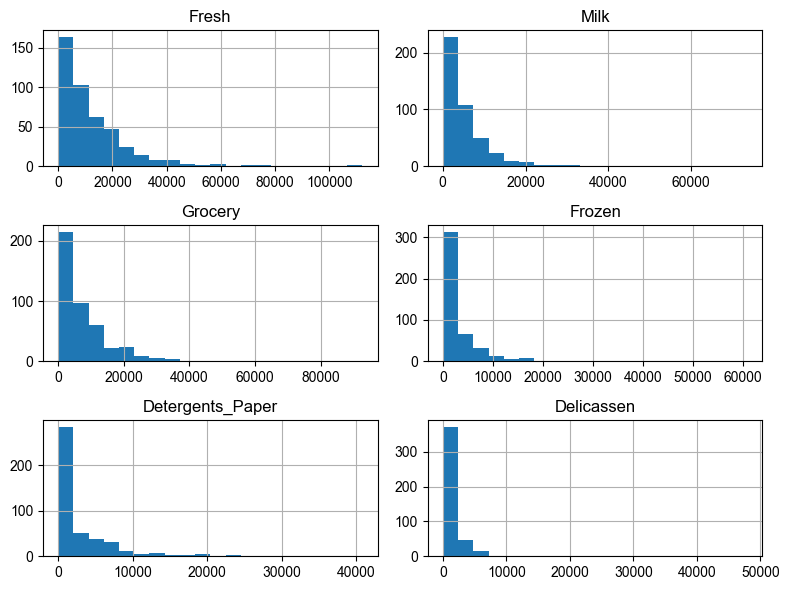

In [6]:
X.hist(bins=20, figsize=(8, 6))
plt.tight_layout()
plt.show()

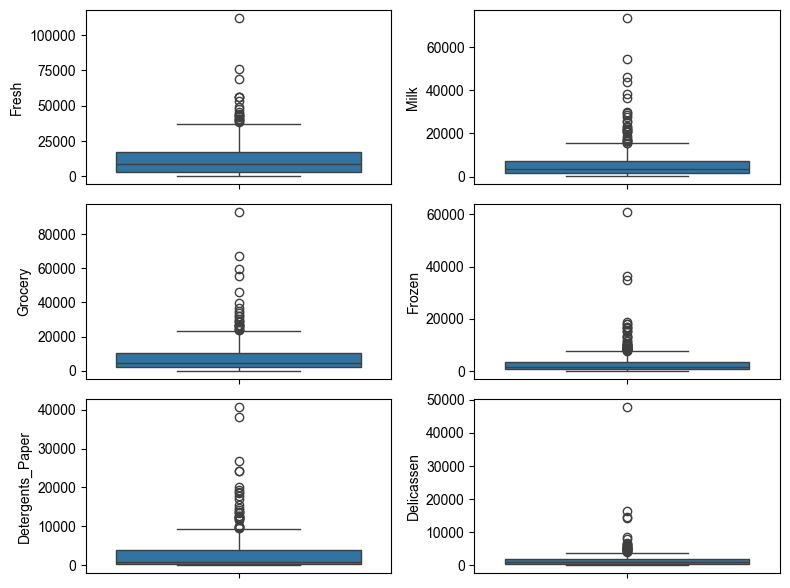

In [12]:
import seaborn as sns
plt.figure(figsize=(8, 6))
for idx in range(6):
    plt.subplot(3, 2, idx + 1)          # idx+1 -> 1,2,3,4 (subplot comeca em 1)
    col = X.columns[idx]
    sns.boxplot(data=X, y=col)

plt.tight_layout()
plt.show()

In [19]:
X_lnha = np.log1p(X)

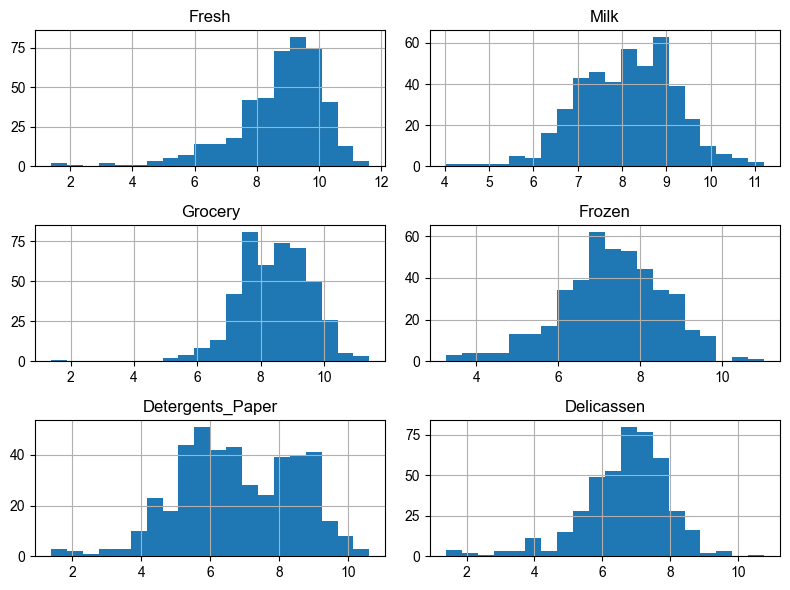

In [21]:
X_lnha.hist(bins=20, figsize=(8, 6))
plt.tight_layout()
plt.show()

In [24]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_lnha = scaler.fit_transform(X_lnha)

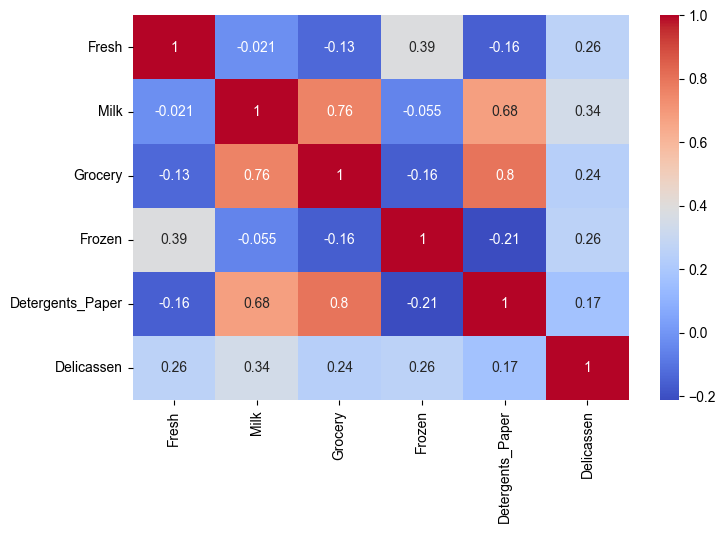

In [27]:
X_plot = pd.DataFrame(X_lnha, columns=X.columns, index=X.index)

corr = X_plot.corr() 
sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.show()